In [1]:
from pathlib import Path
import anndata as ad

data_dir = Path("/work/magroup/skrieger/Syndri/data/xenium_noise_experiment")
files = sorted(data_dir.glob("GSM950*_1pct.h5ad"))

# for path in files:
#     adata = ad.read_h5ad(path)

#     if "admix_probs_optimized_unexpressedgenes_withquerycelltype_0" not in adata.layers:
#         print(f"missing source layer: {path.name}")
#         continue

#     adata.layers["admix_probs_optimized_unexpressedgenes_withquerycelltype_X"] = (
#         adata.layers["admix_probs_optimized_unexpressedgenes_withquerycelltype_0"].copy()
#     )
#     del adata.layers["admix_probs_optimized_unexpressedgenes_withquerycelltype_0"]

#     adata.write_h5ad(path)
#     print(f"renamed layer in {path.name}")

In [10]:
filepath = [str(f) for f in list(files) if "B6_" in str(f)][0]

adata = ad.read_h5ad(filepath)


In [12]:
adata.X

<Compressed Sparse Row sparse matrix of dtype 'int32'
	with 3953218 stored elements and shape (94935, 277)>

(np.float64(152.48209991455076),
 np.float64(7164.587022399903),
 np.float64(416.2112518310547),
 np.float64(5887.924185180664))

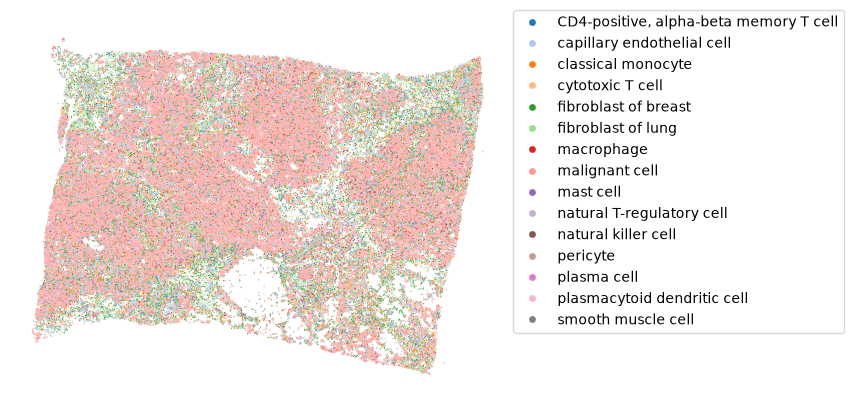

In [13]:
import seaborn as sns
ax=sns.scatterplot(data=adata.obs,x='x_centroid',y='y_centroid',hue='harmony_cell_type',s=1,palette='tab20')
ax.legend(bbox_to_anchor=(1,1.05),markerscale=5)
ax.axis('off')

In [ ]:
import numpy as np
from sklearn.decomposition import PCA
from umap import UMAP

prob_layer = "admix_probs_optimized_unexpressedgenes_withquerycelltype_X"

percentiles = [50, 60, 70, 80, 90, 95, 99]

X_raw = adata.X.toarray().copy()
probs = adata.layers[prob_layer].toarray()

# Calculate thresholds over nonzero probabilities
nonzero_probs = probs[probs > 0]

threshold_info = {}

# Raw + percentile-based conditions
conditions = [("raw", None)]

for percentile in percentiles:
    threshold = np.percentile(nonzero_probs, percentile)
    conditions.append((f"p{percentile}", threshold))

for name, threshold in conditions:

    X = X_raw.copy()

    if threshold is not None:
        removal_mask = (probs > threshold) & (X_raw > 0)
        X[probs > threshold] = 0

        threshold_info[name] = {
            "percentile": int(name[1:]),
            "threshold": threshold,
            "n_removed": removal_mask.sum(),
            "fraction_expressed_removed": (
                removal_mask.sum() / (X_raw > 0).sum()
            )
        }

        print(
            f"{name:>4} | "
            f"threshold = {threshold:.4f} | "
            f"expressed entries removed = "
            f"{removal_mask.sum() / (X_raw > 0).sum():.4f}"
        )

    else:
        print(" raw | no transcript removal")

        threshold_info[name] = {
            "percentile": None,
            "threshold": None,
            "n_removed": 0,
            "fraction_expressed_removed": 0.0
        }

    # Standardize genes
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0)
    std[std == 0] = 1

    X = (X - mean) / std

    # PCA
    X_pca = PCA(
        n_components=30,
        random_state=42
    ).fit_transform(X)

    # UMAP
    coords = UMAP(
        n_components=2,
        random_state=42
    ).fit_transform(X_pca)

    # Save
    adata.obsm[f"X_umap_prob_{name}"] = coords

 raw | no transcript removal


/home/jwinchel/miniconda3/envs/zhuang-merfish/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


 p50 | threshold = 0.7821 | expressed entries removed = 0.0752


/home/jwinchel/miniconda3/envs/zhuang-merfish/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


 p60 | threshold = 0.8892 | expressed entries removed = 0.0601


/home/jwinchel/miniconda3/envs/zhuang-merfish/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


... (6 outputs left out)

 p95 | threshold = 0.9991 | expressed entries removed = 0.0075


/home/jwinchel/miniconda3/envs/zhuang-merfish/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


 p99 | threshold = 0.9999 | expressed entries removed = 0.0015


/home/jwinchel/miniconda3/envs/zhuang-merfish/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


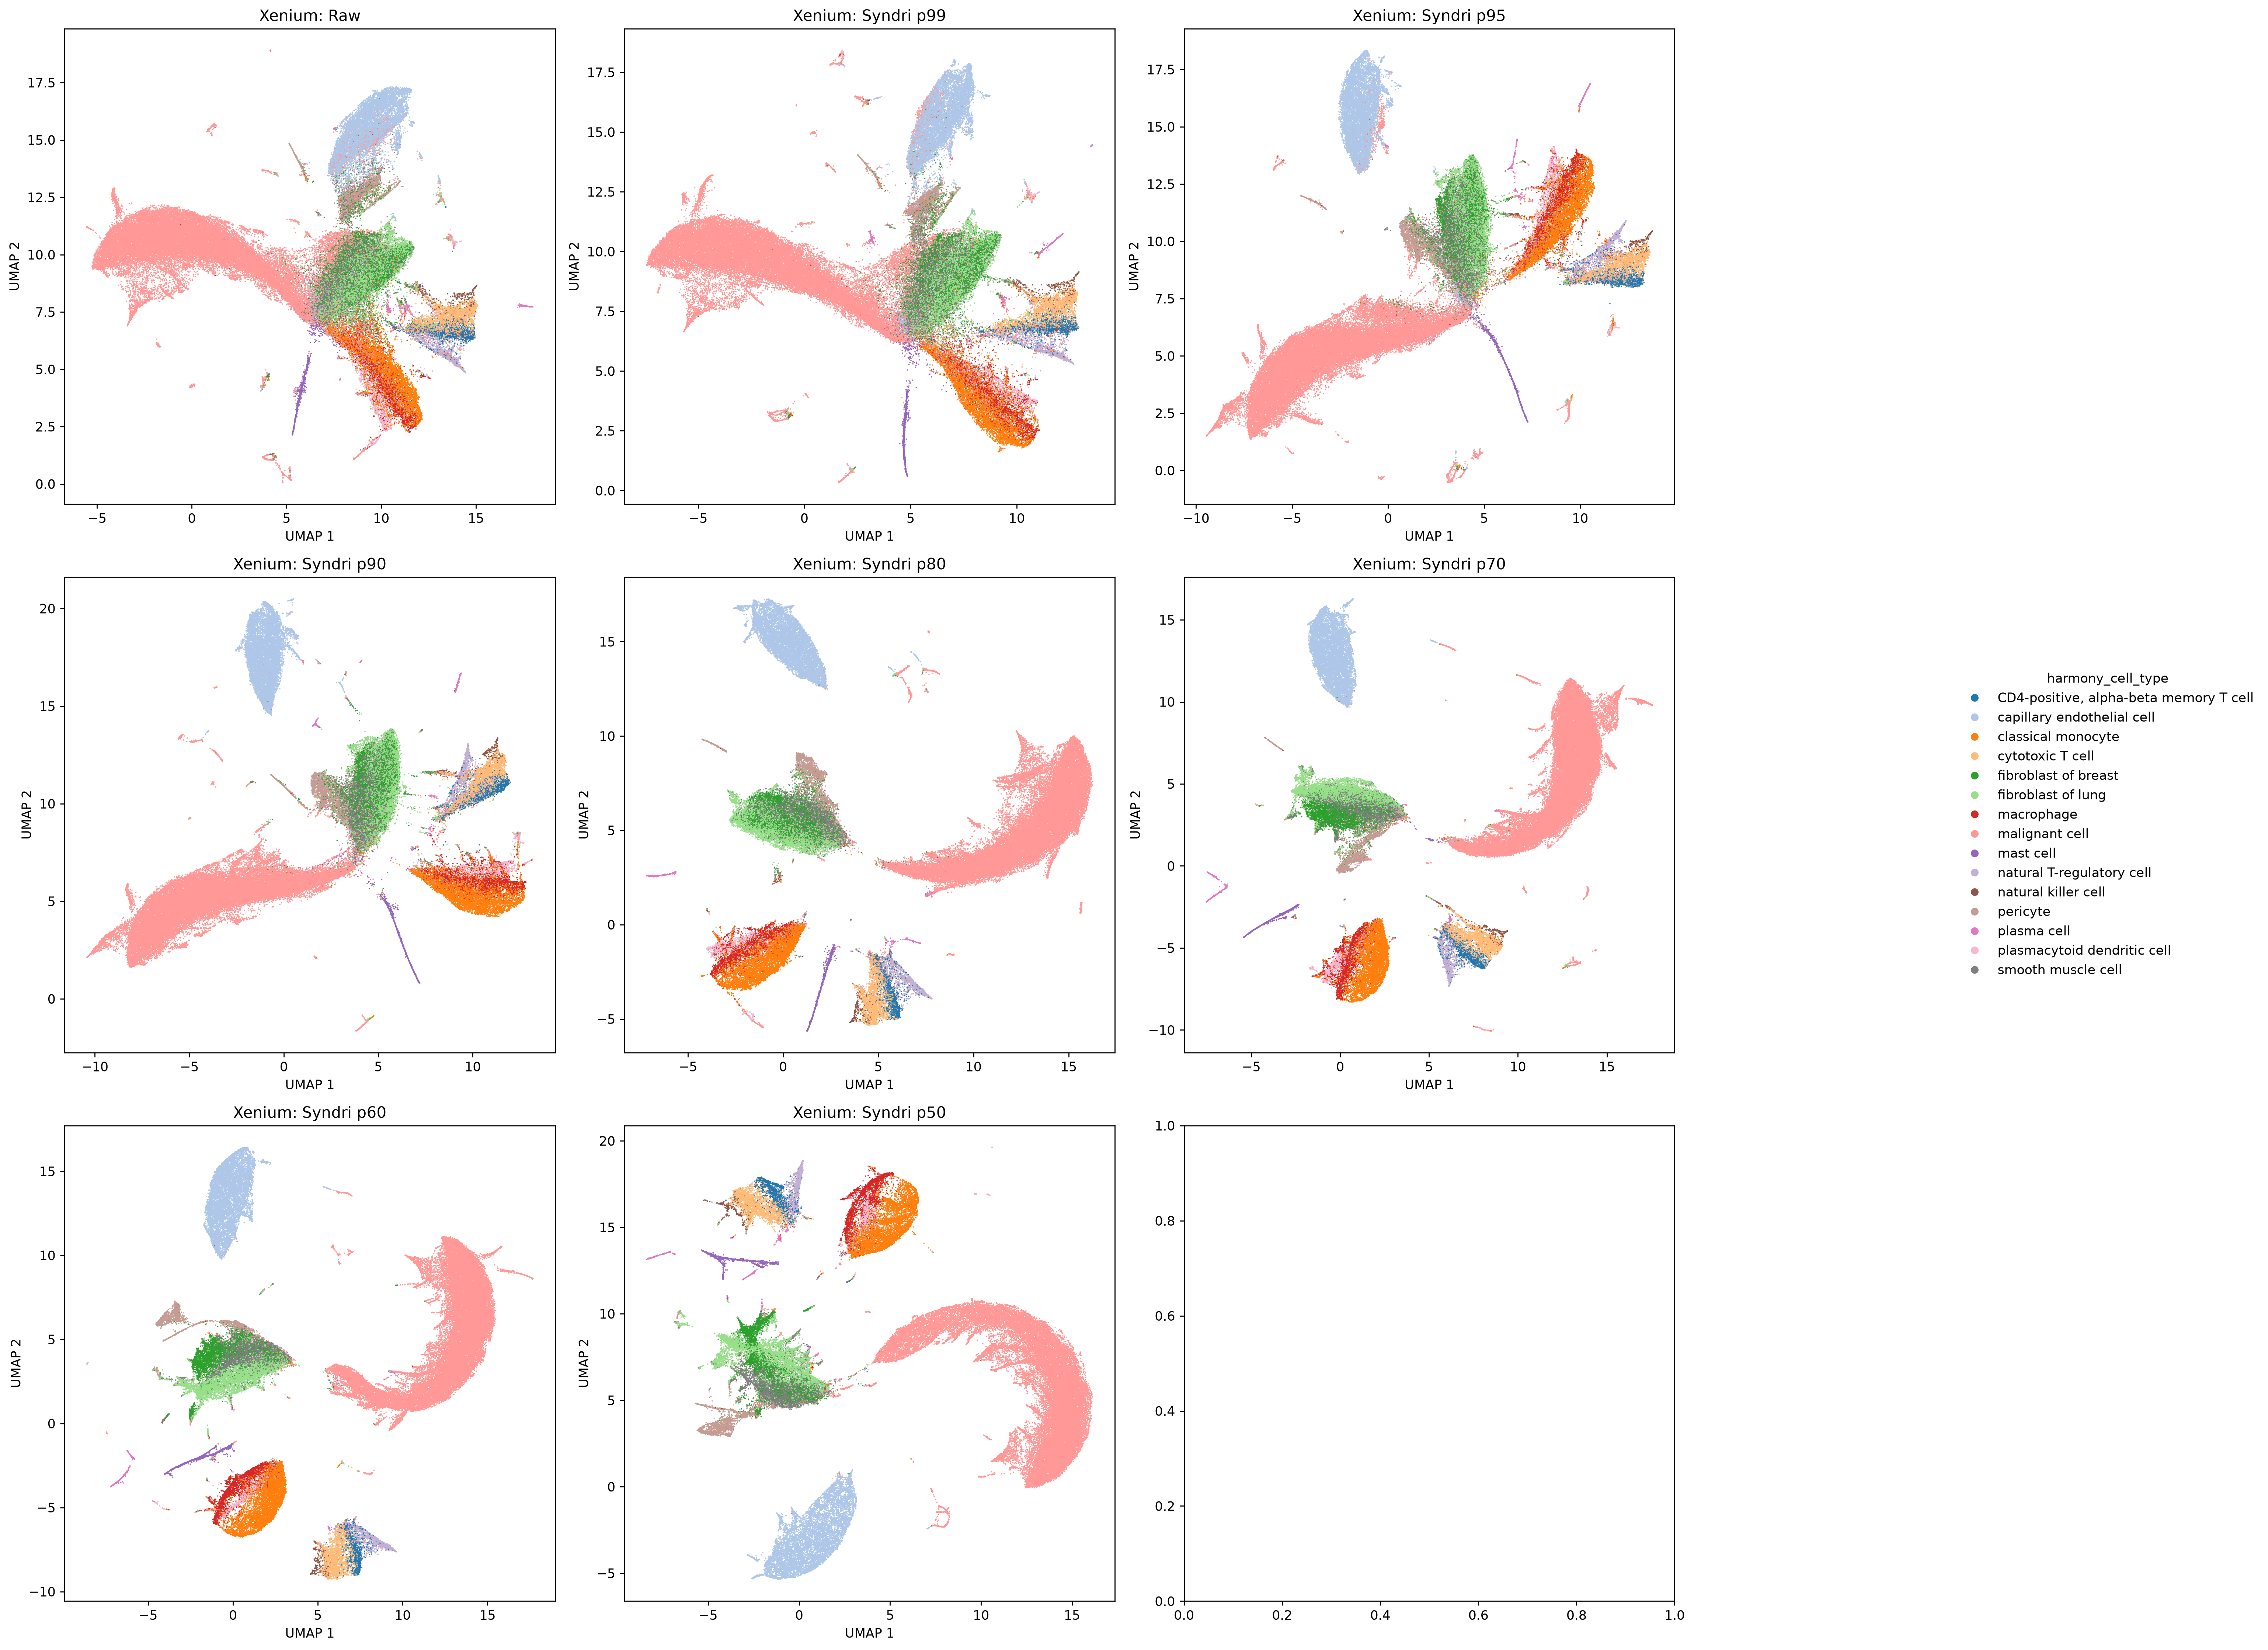

In [15]:
import math
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# Plot from least aggressive -> most aggressive cleaning
conditions = [
    ("raw", "Xenium: Raw"),
    ("p99", "Xenium: Syndri p99"),
    ("p95", "Xenium: Syndri p95"),
    ("p90", "Xenium: Syndri p90"),
    ("p80", "Xenium: Syndri p80"),
    ("p70", "Xenium: Syndri p70"),
    ("p60", "Xenium: Syndri p60"),
    ("p50", "Xenium: Syndri p50"),
]

hue_col = "harmony_cell_type"

# ------------------------------------------------------------------
# Define ONE color mapping shared across every subplot
# ------------------------------------------------------------------

cell_types = sorted(adata.obs[hue_col].dropna().unique())

colors = sns.color_palette("tab20", n_colors=len(cell_types))

palette = dict(zip(cell_types, colors))

# ------------------------------------------------------------------
# Set up subplot grid
# ------------------------------------------------------------------

ncols = 3
nrows = math.ceil(len(conditions) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(7 * ncols, 6 * nrows),
    dpi=250
)

axes = axes.flat

# ------------------------------------------------------------------
# Plot each UMAP
# ------------------------------------------------------------------

for ax, (condition, title) in zip(axes, conditions):

    coords = adata.obsm[f"X_umap_prob_{condition}"]

    sns.scatterplot(
        data=adata.obs,
        x=coords[:, 0],
        y=coords[:, 1],
        hue=hue_col,
        hue_order=cell_types,
        palette=palette,
        s=1,
        linewidth=0,
        legend=False,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")

# Turn off unused subplot(s)
for ax in list(axes)[len(conditions):]:
    ax.axis("off")

# ------------------------------------------------------------------
# Create one shared legend
# ------------------------------------------------------------------

legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markerfacecolor=palette[cell_type],
        markeredgecolor="none",
        markersize=6,
        label=cell_type
    )
    for cell_type in cell_types
]

fig.legend(
    handles=legend_handles,
    labels=cell_types,
    title=hue_col,
    bbox_to_anchor=(1.01, 0.5),
    loc="center left",
    frameon=False
)

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

[0.05481629 0.23879308 0.44706646 0.63137465 0.78207937 0.97187126]


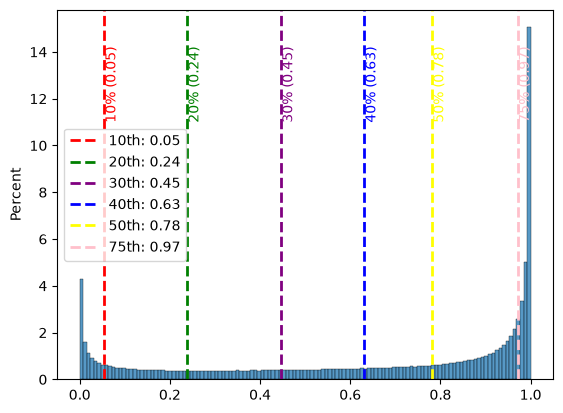

In [16]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
pvals = adata.layers['admix_probs_optimized_unexpressedgenes_withquerycelltype_X'].toarray().ravel()
counts = adata.X.toarray().ravel()

pvals_nonzero = pvals[counts > 0]
data = pvals_nonzero
# sns.histplot(x=pvals_nonzero)
# Create the histplot
ax = sns.histplot(data, stat="percent")

# Calculate percentiles (e.g., 25th, 50th, 75th)
percentiles = [10, 20, 30, 40, 50, 75]
values = np.percentile(data, percentiles)
print(values)

# Plot vertical lines and labels
colors = ["red", "green", "purple","blue","yellow","pink"]
for p, val, color in zip(percentiles, values, colors):
  ax.axvline(val, color=color, linestyle="--", linewidth=2, label=f"{p}th: {val:.2f}")
  # Add text annotation near the top of the plot
  ax.text(
      val,
      ax.get_ylim()[1] * 0.9,
      f" {p}% ({val:.2f})",
      color=color,
      rotation=90,
      verticalalignment="top",
  )

plt.legend()
plt.show()

In [5]:
adata = ad.read_h5ad('/work/magroup/shared/tissueFM/processed_data/zhuang/scfm/pretrain/0.h5ad')
adata.obs['cell_label']

237969407200283353425343368802596655973    237969407200283353425343368802596655973
112732736601068885348393944654633454474    112732736601068885348393944654633454474
117750215352927249265215787923412342338    117750215352927249265215787923412342338
119762943164481505976979859358490769206    119762943164481505976979859358490769206
121008072809942138107320330714923010875    121008072809942138107320330714923010875
                                                            ...                   
297209407269778071108946499038127298664    297209407269778071108946499038127298664
302172096957943182136477338762842553829                                        nan
317816278265681966681044964291699028175                                        nan
334226335185227821419833937751823896818    334226335185227821419833937751823896818
94658190611442534849529066729546741422                                         nan
Name: cell_label, Length: 26020, dtype: category
Categories (25766, str): ['21037989137

In [22]:
import os
adata = ad.read_h5ad(os.path.join(data_dir,files[1]))


In [ ]:
import seaborn as sns


In [71]:
pvals = adata.layers['admix_probs_matchedcelltypes_optimized_X'].toarray().ravel()
counts = adata.X.toarray().ravel()
tot = len(pvals[counts>0])
num = len(pvals[(pvals>0.95)])
print(num/tot)

0.4813082648534445


0.9465419054031372


<Axes: ylabel='Count'>

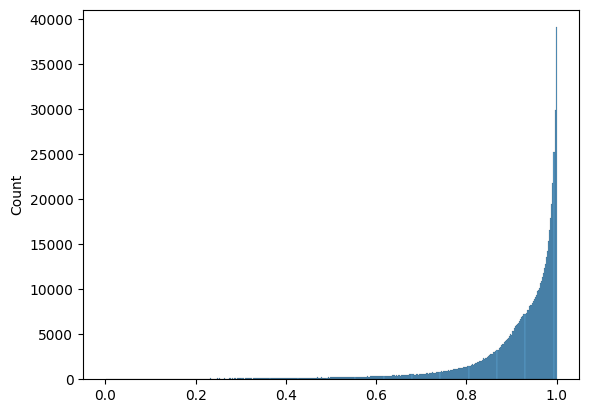

In [ ]:
import numpy as np
pvals = adata.layers['admix_probs_matchedcelltypes_optimized_X'].toarray().ravel()
counts = adata.X.toarray().ravel()

pvals = pvals[counts>0]
print(np.percentile(pvals,50))
sns.histplot(x=pvals)

In [76]:
from umap import UMAP
import scanpy as sc
from sklearn.decomposition import PCA
counts = adata.X.toarray()

pvals = adata.layers['admix_probs_trial_0'].toarray()

# counts[pvals>0.95] = (1-pvals[pvals>0.95])*counts[pvals>0.95]
counts[pvals>0.95] = 0

counts = (counts-np.mean(counts,axis=0))/(np.std(counts,axis=0))

pcs = PCA(n_components=30).fit_transform(counts)

coords = UMAP(n_components=2).fit_transform(pcs) 

adata.obsm['UMAP_cleaned'] = coords

In [77]:
from umap import UMAP
import scanpy as sc
from sklearn.decomposition import PCA
counts = adata.X.toarray()

pvals = adata.layers['admix_probs_matchedcelltypes_optimized_X'].toarray()

# counts[pvals>0.99] = 0

counts = (counts-np.mean(counts,axis=0))/(np.std(counts,axis=0))

pcs = PCA(n_components=30).fit_transform(counts)

coords = UMAP(n_components=2).fit_transform(pcs) 

adata.obsm['UMAP_raw'] = coords

Text(0.5, 1.0, 'Cleaned (pval>0.95 set to 0)')

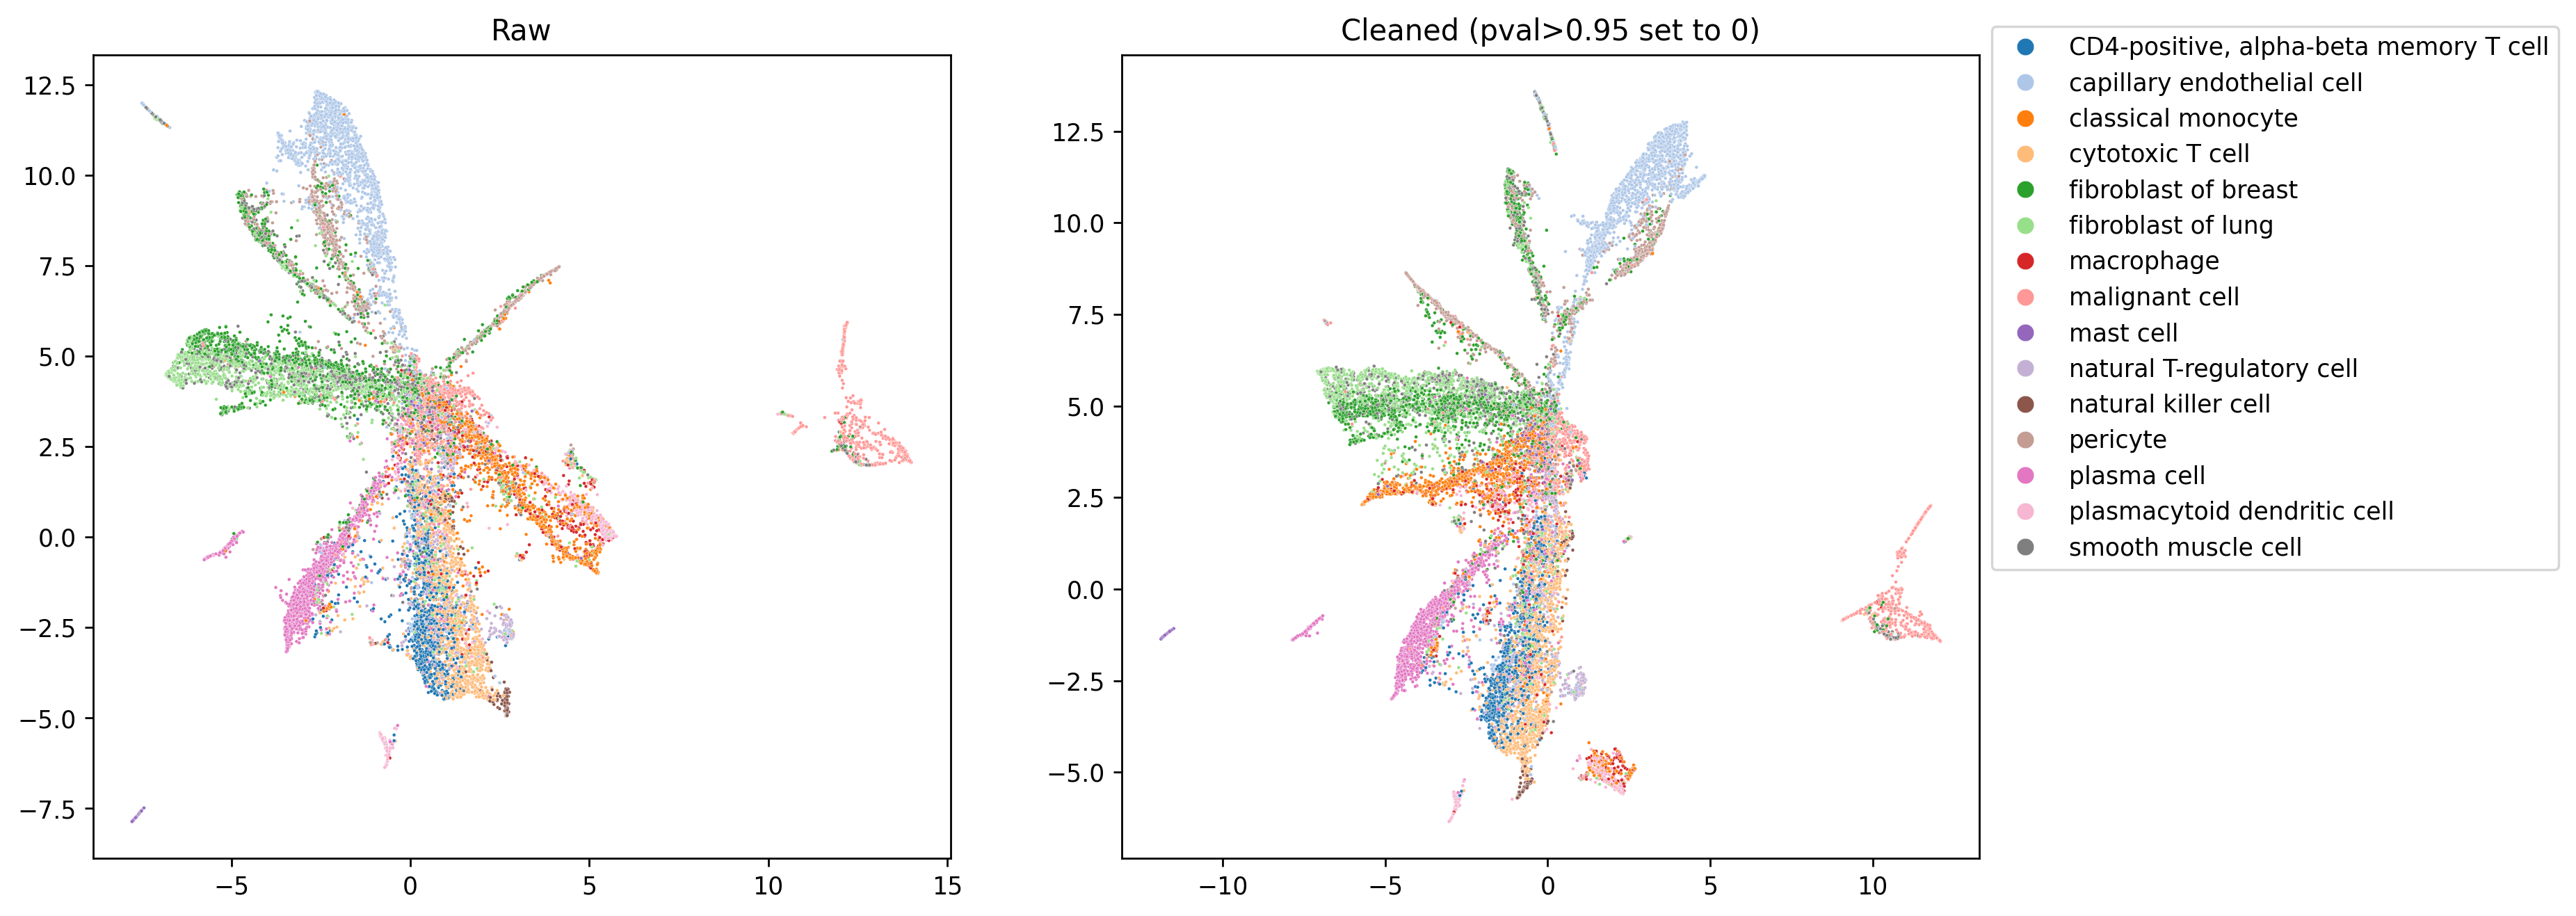

In [84]:
import matplotlib.pyplot as plt

fig,axes = plt.subplots(nrows=1,ncols=2,figsize=(14,6),dpi=250)

ax = axes[0]
ax = sns.scatterplot(x=adata.obsm['UMAP_raw'][:,0],y=adata.obsm['UMAP_raw'][:,1],hue=adata.obs['harmony_cell_type'],palette='tab20',s=2,ax=ax,legend=False)
ax.set_title('Raw')

ax = axes[1]
ax = sns.scatterplot(x=adata.obsm['UMAP_cleaned'][:,0],y=adata.obsm['UMAP_cleaned'][:,1],hue=adata.obs['harmony_cell_type'],palette='tab20',s=2,ax=ax)
ax.legend(bbox_to_anchor=(1,1.05),markerscale=5)
ax.set_title('Cleaned (pval>0.95 set to 0)')